In [74]:
# dataset setup
!uv add ucimlrepo torch numpy matplotlib
from ucimlrepo import fetch_ucirepo 
import torch
from torch.utils.data import random_split, TensorDataset
import matplotlib.pyplot as plt

%matplotlib inline

# fetch dataset 
banknote_authentication = fetch_ucirepo(id=267) 

Resolved 65 packages in 7ms
Checked 45 packages in 10ms


In [125]:
# dataset paration (70% training, 30% validation)
X = torch.Tensor(banknote_authentication.data.features.to_numpy())
y = torch.Tensor(banknote_authentication.data.targets.to_numpy())
dataset = TensorDataset(X, y)
rng = torch.Generator().manual_seed(598)
train_set, test_set = random_split(
    dataset,
    [0.7, 0.3],
    generator=rng,
)
print("Dataset size:", len(dataset))
print("Training set size", len(train_set))
print("Test set size", len(test_set))

Dataset size: 1372
Training set size 961
Test set size 411


In [96]:
# convert to torch tensors
X_train = torch.cat([sample[0].unsqueeze(0) for sample in train_set], dim=0)
y_train = torch.cat([sample[1].unsqueeze(0) for sample in train_set], dim=0).squeeze(1)
X_test = torch.cat([sample[0].unsqueeze(0) for sample in test_set], dim=0)
y_test = torch.cat([sample[1].unsqueeze(0) for sample in test_set], dim=0).squeeze(1)

In [102]:
# linear regression
X_train_bias = torch.cat([X_train, torch.ones((len(X_train), 1))], dim=1)
X_test_bias = torch.cat([X_test, torch.ones((len(X_test), 1))], dim=1)
w = torch.linalg.lstsq(X_train_bias, y_train).solution
results = X_test_bias @ w
preds = (results > 0.5).int()
lr_error_rate = (preds != y_test).float().mean()
print("Linear Regression Error Rate:", lr_error_rate.item())


Linear Regression Error Rate: 0.012165450491011143


In [118]:
# knn (scikit-learn)
from sklearn.neighbors import KNeighborsClassifier

ks = list(range(1, 21))
knn_error_rates = []
for k in ks:
    model = KNeighborsClassifier(
        n_neighbors=k,
        metric='euclidean',
    )
    model.fit(X_train, y_train)
    results = torch.from_numpy(model.predict(X_test))
    knn_error_rates.append((y_test != results).float().mean().item())

## Problem 1 (a). Plot the two errors (misclassification rate on the test set)

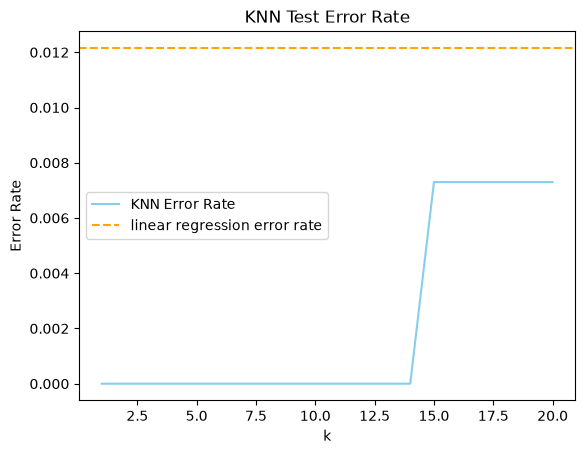

In [119]:
plt.plot(
    ks, knn_error_rates,
    label="KNN Error Rate",
    color="skyblue"
)
plt.xlabel("k")
plt.ylabel("Error Rate")
plt.title("KNN Test Error Rate")
plt.axhline(lr_error_rate, color="orange", linestyle="--", label="linear regression error rate")
plt.legend()
plt.show()

## 

## Problem 1 (b). Discuss whether the plot matches the intuition of bias-variance trade-off 

The plot does not fully match the intuition of the bias-variance trade-off because the test error stays 0 even at $k = 1$. The expected left branch of the U-shape, where flexible fit overfits, is absent. However, the right branch of the U-shape does appear. When the model complexity decreases $(k \uparrow)$, the plot does show an increase of the error rate when $k \ge 15$. 
Therefore, the optimal choices of $k$ would be 
$$
k \in \{1, \dots, 14\}
$$ 

with degrees of freedom 

$$
dof = \frac{961}{k} \in \{961.00,\ 480.50,\ 320.33,\ 240.25,\ 192.20,\ 160.17,\ 137.29,\ 120.13,\ 106.78,\ 96.10,\ 87.36,\ 80.08,\ 73.92,\ 68.64\}
$$

and 
$$
error\ rate = 0
$$

In [124]:
len(X_test) / torch.Tensor(ks)

tensor([411.0000, 205.5000, 137.0000, 102.7500,  82.2000,  68.5000,  58.7143,
         51.3750,  45.6667,  41.1000,  37.3636,  34.2500,  31.6154,  29.3571,
         27.4000,  25.6875,  24.1765,  22.8333,  21.6316,  20.5500])

## Problem 2 (a). 

Generate 3 independent standard Normal variables X1, X2, X3 of n = 1000 independent observations. Generate the response Y from the following nonlinear model: 

$$
Y = X_1 + 2 \cdot X_2 - X_3 + 0.5 \cdot X_1 X_2 + \varepsilon
$$

where

$$
\varepsilon \sim \ i.i.d.\ \mathcal{N} (0, 1)
$$

In [127]:
torch.manual_seed(598)
n = 1000
X = torch.randn(n, 3)
epsilon = torch.randn(n)

Y = X[:, 0] + 2 * X[:, 1] - X[:, 2] + 0.5 * X[:, 0] * X[:, 1] + epsilon

## Problem 2 (b). 
Use the appropriate built-in kNN function in Python (Euclidean distance) and report the mean squared error (MSE) on the test set for $k = 1, 5, 10, 20$. Use the first 500 observations as the training data and the remaining 500 as the testing data.

In [139]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

ks = [1, 5, 10, 20]
X_train, X_test = X[:500, :], X[500:, :]
y_train, y_test = Y[:500], Y[500:]
losses = []

for k in ks:
    model = KNeighborsRegressor(
        n_neighbors=k,
        metric="euclidean"
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    loss = mean_squared_error(y_test, preds)
    losses.append(loss)
    print(f"k = {k}\tMSE = {loss}")

k = 1	MSE = 2.1315810680389404
k = 5	MSE = 1.2812800407409668
k = 10	MSE = 1.2320960760116577
k = 20	MSE = 1.3567724227905273


## Problem 2 (c). write my own KNN

In [142]:
def mse(y_true: list[float], y_pred: list[float]):
    if len(y_true) != len(y_pred):
        raise ValueError("The length of the two lists should be the same")
    
    total = 0
    for y_t, y_p in zip(y_true, y_pred):
        total += (y_t - y_p) ** 2
    return total / len(y_true)

def euclidean(a: list[float], b: list[float]):
    if len(a) != len(b):
        raise ValueError("The length of the two lists should be the same")
    
    import math
    distance_2 = 0
    for a_i, b_i in zip(a, b):
        distance_2 += (a_i - b_i) **2
    return math.sqrt(distance_2)

def knn(xtrain, ytrain, xtest, k):
    y_test = []
    for x_v in xtest:
        distances = []
        for x_t, y_t in zip(xtrain, ytrain):
            dist = euclidean(x_v, x_t)
            distances.append((dist, y_t))
        distances.sort(key=lambda x: x[0])
        
        avg = 0
        neighbors = distances[:k]
        for neighbor in neighbors:
            avg += neighbor[1]
        y_test.append(avg / k)
    return y_test

losses = []

for k in ks:
    preds = knn(X_train.tolist(), y_train.tolist(), X_test.tolist(), k)
    loss = mse(y_test, preds)
    losses.append(loss)
    print(f"k = {k}\tMSE = {loss}")

k = 1	MSE = 2.131580352783203
k = 5	MSE = 1.2812795639038086
k = 10	MSE = 1.2320961952209473
k = 20	MSE = 1.3567726612091064
